# Data and setup
What the validation is built on, before any method is run.

- **Unit:** a *player-season* = a player's Fall regular-season matches in one year (matches with minutes > 0). Each is labelled with the tactical position group (7 groups) where they played most minutes; player-seasons with an unmapped position or a tied top group are dropped.
- **Truth set:** player-seasons with at least 900 minutes. The truth for each is its **full-season per-90** of every volume stat.
- **Low-minute samples:** for each truth player-season, one **prefix** after every match played: the player's first *k* matches in date order, as long as the cumulative minutes are at most 750. Stats are summed over the prefix and converted to per-90 with the prefix's actual minutes. Training and test rows are these prefixes; the target is the season's full per-90.
- **Volume stats** = every per-90 count (shots, passes, tackles...) plus the derived counts from `wyscout/derived.py`. Rates, ratios and percents are never estimated: they are rebuilt from the estimated volumes.
- Female and male are always run separately.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)
from low_minute_player_analysis import checkpoints, stat_groups, rate_rebuild
truth = {g: pd.read_parquet(checkpoints.RESULTS_DIR / f"truth_{g}.parquet") for g in ("female", "male")}
prefixes = {g: pd.read_parquet(checkpoints.RESULTS_DIR / f"prefixes_{g}.parquet") for g in ("female", "male")}
try:
    from low_minute_player_analysis import common
    con = common.connect()
    DB = True
except Exception as e:                      # no credentials / no network: the DB-only cells are skipped
    con, DB = None, False
    print("database not available, skipping database cells:", type(e).__name__)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


**Building the data files (optional).** `truth_*.parquet` and `prefixes_*.parquet` in `results/` are created from the database by `checkpoints.build_and_save_data`. They already exist; set `BUILD_DATA = True` to rebuild them (takes several minutes).

In [2]:
BUILD_DATA = False
if BUILD_DATA and DB:
    checkpoints.build_and_save_data(con)
    truth = {g: pd.read_parquet(checkpoints.RESULTS_DIR / f"truth_{g}.parquet") for g in ("female", "male")}
    prefixes = {g: pd.read_parquet(checkpoints.RESULTS_DIR / f"prefixes_{g}.parquet") for g in ("female", "male")}

## 1. How many player-seasons?

In [3]:
if DB:
    from low_minute_player_analysis import audit_counts
    keep, reasons = audit_counts.assign_groups(audit_counts.load_matches(con))
    print("Player-seasons and why some are dropped (reasons overlap):", reasons)
    display(audit_counts.counts_table(keep).round(0))
else:
    print("(needs the database) showing the 900+ minute truth set only")
t = pd.concat({g: d for g, d in truth.items()}, names=["gender"]).reset_index(level=0)
display(t.groupby(["gender", "group"]).agg(player_seasons=("player_id", "size"), players=("player_id", "nunique"),
                                            median_minutes=("full_minutes", "median"), median_matches=("full_matches", "median")).round(0))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Player-seasons and why some are dropped (reasons overlap): {'player_seasons': 95310, 'with_unmapped_position': 495, 'tied_top_group': 219, 'kept': 94596}


,gender,group,all_player_seasons,median_minutes,>=600,>=750,>=900,>=1200
0,female,Attacking Midfielders,7521,467.0,3159,2491,1941,948
1,female,Center Backs,8556,922.0,5233,4783,4346,3272
2,female,Center Forwards,9021,435.0,3594,2808,2137,985
3,female,Central Midfielders,12047,587.0,5936,5103,4250,2524
4,female,GK,4929,469.0,2275,2048,1817,1340
5,female,Outside Backs,10799,546.0,5127,4324,3638,2270
6,female,Wingers,4621,363.0,1649,1280,978,424
7,male,Attacking Midfielders,4071,485.0,1781,1469,1143,549
8,male,Center Backs,5921,852.0,3436,3145,2856,2180
9,male,Center Forwards,5909,453.0,2432,1942,1487,692


player_seasons  players  median_minutes  \
gender group                                                            
female Attacking Midfielders            1941     1500          1190.0   
       Center Backs                     4346     2621          1442.0   
       Center Forwards                  2137     1494          1171.0   
       Central Midfielders              4250     2683          1273.0   
       GK                               1817     1044          1446.0   
       Outside Backs                    3638     2367          1297.0   
       Wingers                           978      803          1158.0   
male   Attacking Midfielders            1143      913          1189.0   
       Center Backs                     2856     1765          1442.0   
       Center Forwards                  1487     1048          1177.0   
       Central Midfielders              2801     1769          1301.0   
       GK                               1170      694          1497.0   
       Outside Backs                    2420     1636          1329.0   
       Wingers                           896      726          1168.0   

                              median_matches  
gender group                                  
female Attacking Midfielders            17.0  
       Center Backs                     16.0  
       Center Forwards                  17.0  
       Central Midfielders              17.0  
       GK                               15.0  
       Outside Backs                    17.0  
       Wingers                          17.0  
male   Attacking Midfielders            16.0  
       Center Backs                     15.0  
       Center Forwards                  16.0  
       Central Midfielders              16.0  
       GK                               15.0  
       Outside Backs                    16.0  
       Wingers                          17.0

The truth set (900+ minutes) is a minority of all player-seasons: most players play fewer minutes. That is the population the final model is meant for, and why the validation replays 900+ minute players at low minutes.

## 2. Prefixes: one low-minute sample per match played
One example player-season (male Wingers). Each row is what a scout would have known after that many matches.

,n_matches,actual_minutes,low_shots,low_passes,low_key_passes
0,1,101.0,1.78,40.99,0.00
1,2,160.0,3.38,39.94,1.12
2,3,258.0,2.79,35.58,0.70
3,4,322.0,2.24,32.14,0.56
4,5,403.0,2.23,33.95,0.67
5,6,474.0,2.09,32.47,0.57
6,7,563.0,2.08,33.25,0.48
7,8,653.0,1.93,31.84,0.41
8,9,732.0,1.84,31.60,0.37


Full season: 17 matches, 1346 minutes, shots 2.07, passes 33.63, key passes 0.33 per 90


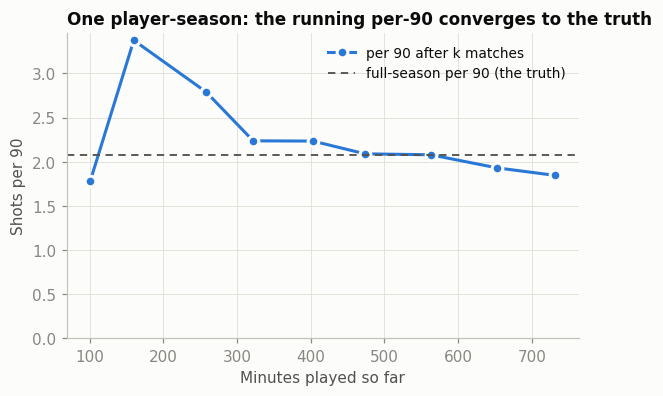

In [4]:
pre = prefixes["male"]; tr = truth["male"]
ex = pre[pre.group == "Wingers"].groupby(["player_id", "year"]).size()
pid, yr = ex[ex == 9].index[3]
d = pre[(pre.player_id == pid) & (pre.year == yr)].sort_values("n_matches")
full = tr[(tr.player_id == pid) & (tr.year == yr)].iloc[0]
cols = ["n_matches", "actual_minutes", "low_shots", "low_passes", "low_key_passes"]
display(d[cols].round(2).reset_index(drop=True))
print(f"Full season: {full.full_matches:.0f} matches, {full.full_minutes:.0f} minutes, shots {full.full_shots:.2f}, passes {full.full_passes:.2f}, key passes {full.full_key_passes:.2f} per 90")
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(d["actual_minutes"], d["low_shots"], marker="o", ms=7, lw=2, color=nh.COLORS["shrink"], markeredgecolor=nh.SURFACE, markeredgewidth=2, label="per 90 after k matches")
ax.axhline(full.full_shots, color=nh.INK2, lw=1.2, ls=(0, (4, 3)), label="full-season per 90 (the truth)")
ax.set_xlabel("Minutes played so far"); ax.set_ylabel("Shots per 90"); ax.set_ylim(bottom=0)
ax.set_title("One player-season: the running per-90 converges to the truth", loc="left"); ax.legend(); plt.show()

### Minutes bins and weights
Scores are reported in three bins of the prefix's minutes: **250 = 0-375**, **500 = 375-625**, **750 = 625-750**. A player-season has several prefixes in a bin, so every row gets weight 1 / (rows of that season in the bin): each player-season counts once per bin, in training and in scoring.

In [5]:
stems, folds = ev.group_setup("male", "Wingers")
pool = ev.load_pool("male", "Wingers", stems)
display(pool.groupby("bin").agg(prefix_rows=("weight", "size"), player_seasons=("weight", "sum")).round(0))
dd = pool[(pool.player_id == pid) & (pool.year == yr)][["n_matches", "actual_minutes", "bin", "weight"]]
display(dd.round(3).reset_index(drop=True))

,prefix_rows,player_seasons
bin,,
250,4401,896.0
500,3106,896.0
750,1526,896.0


,n_matches,actual_minutes,bin,weight
0,1,101.0,250,0.250
1,2,160.0,250,0.250
2,3,258.0,250,0.250
3,4,322.0,250,0.250
4,5,403.0,500,0.333
5,6,474.0,500,0.333
6,7,563.0,500,0.333
7,8,653.0,750,0.500
8,9,732.0,750,0.500


## 3. Which stats are modelled
Every volume stat with some variation in the group. Goalkeeper-only stats (`gk_*`, goal kicks, `xg_save`, `goals_prevented`) are used for the GK group only. Each stat sits in exactly one functional group (`wyscout/STAT_GROUPS.md`, with `stat_groups.PRIMARY_GROUP` resolving duplicates); these groups are used by `ot_group`.

In [6]:
rows = []
for grp in ["GK", "Wingers"]:
    st, _ = ev.group_setup("male", grp)
    groups, left = stat_groups.stat_to_groups(st)
    rows.append(pd.Series({k: len(v) for k, v in groups.items()}, name=f"{grp} ({len(st)} stats)"))
display(pd.DataFrame(rows).fillna(0).astype(int).T)

,GK (111 stats),Wingers (100 stats)
Shooting,14,14
Chance Creation,16,16
Passing,11,11
Progression,12,12
Dribbling,8,8
Duels,5,5
Aerial,2,4
Defending,12,12
Pressing & Recovery,5,5
Ball Security,6,6


## 4. The raw distributions of stats
Before any model: how does the *raw* low-minute per-90 compare with the full-season per-90 of the same players (male Wingers)? Blue = the truth (full season). Grey outline = the raw per-90 from the prefix (one point per player-season, its longest prefix in the bin). At low minutes the raw distribution is wider and has a spike at exactly 0 (no event yet); both shrink toward the truth as minutes grow.

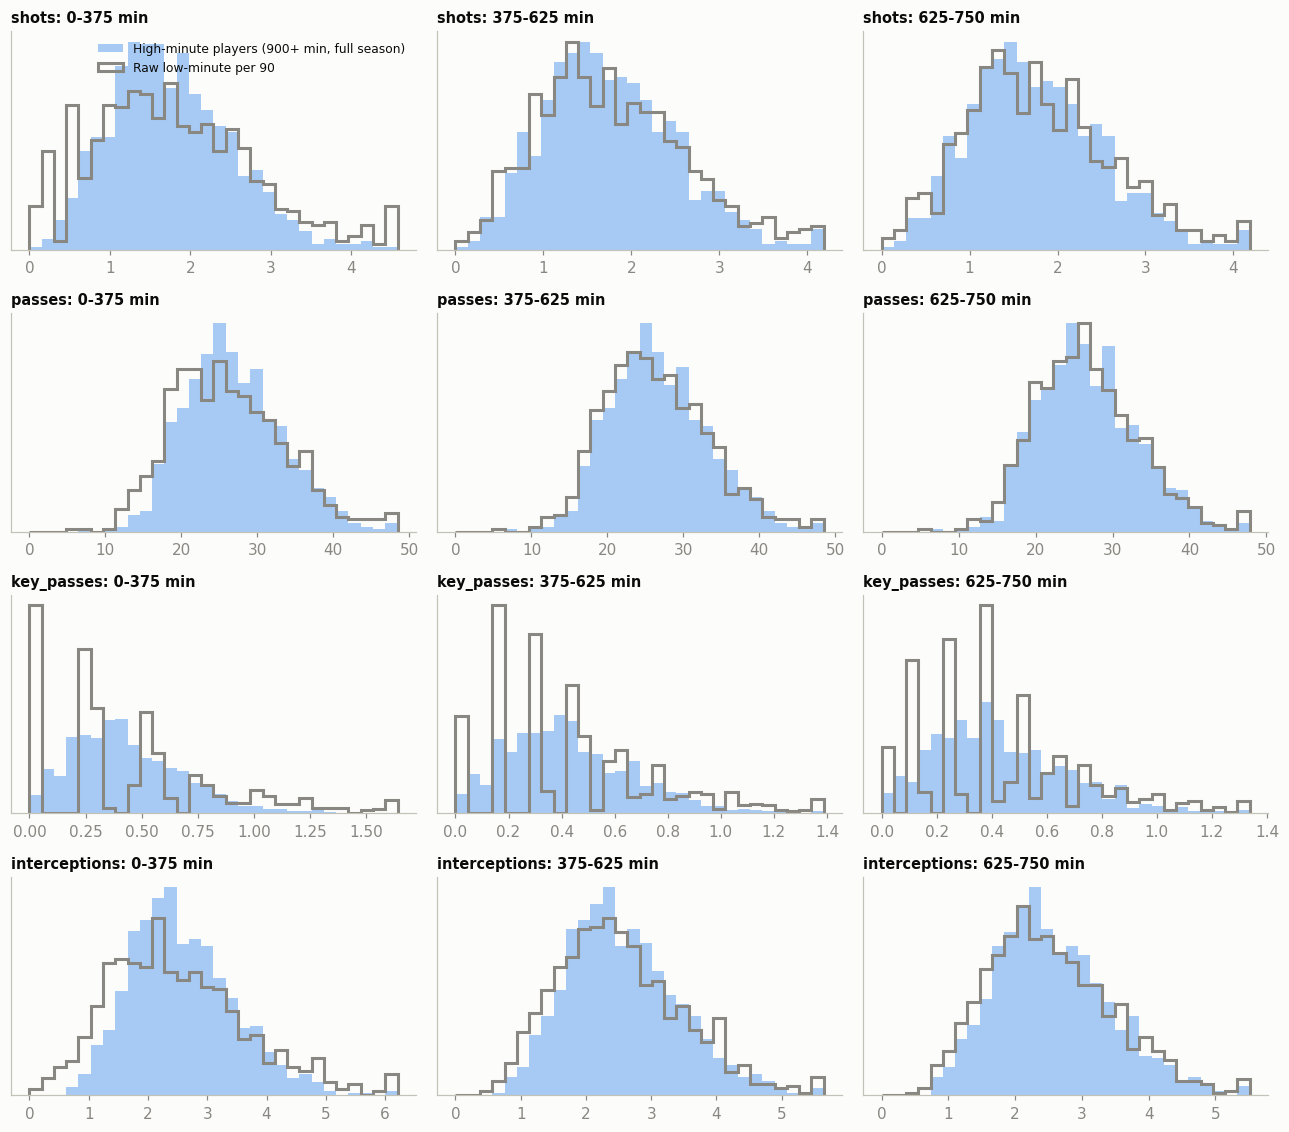

In [7]:
stat_list = ["shots", "passes", "key_passes", "interceptions"]
fig, axes = plt.subplots(len(stat_list), 3, figsize=(12, 2.6 * len(stat_list)))
names = {250: "0-375 min", 500: "375-625 min", 750: "625-750 min"}
for j, b in enumerate((250, 500, 750)):
    sub = pool[pool["bin"] == b].groupby(["player_id", "year"]).tail(1)
    for i, s in enumerate(stat_list):
        nh.overlay_hist(axes[i, j], sub[f"full_{s}"], sub[f"low_{s}"], "Raw low-minute per 90", nh.COLORS["raw"],
                        title=f"{s}: {names[b]}")
axes[0, 0].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

In [8]:
rows = {}
for b in (250, 500, 750):
    sub = pool[pool["bin"] == b].groupby(["player_id", "year"]).tail(1)
    rows[f"shots, raw low-minute, {names[b]}"] = sub["low_shots"]
rows["shots, full season (truth)"] = sub["full_shots"]
display(nh.dist_summary(rows).round(3))

,n,mean,sd,share_zero,p10,median,p90
"shots, raw low-minute, 0-375 min",896.0,1.795,1.010,0.018,0.552,1.687,3.065
"shots, raw low-minute, 375-625 min",896.0,1.784,0.846,0.003,0.777,1.698,2.894
"shots, raw low-minute, 625-750 min",896.0,1.787,0.826,0.001,0.773,1.707,2.909
"shots, full season (truth)",896.0,1.763,0.748,0.000,0.832,1.683,2.767


## 5. Rebuilding rates, ratios and percents from volumes
Estimated per-90 volumes go through the repo's own formulas (`wyscout/derived.py` for engineered shares and ratios, and the `stat_formulas` rules for API percentages), so every formula-based stat stays consistent with its volumes. Ratios are scale-free, so per-90 values can be used directly; a rate is left missing when its denominator is below the minimum used when rolling up seasons.

In [9]:
display(R.drop_duplicates("stat").groupby("stat_type").size().rename("rates scored").to_frame())
if DB:
    all_stems = ev.load_truth("male")[1]
    specs, _ = rate_rebuild.load_specs(con, set(all_stems))
    df = pd.DataFrame([dict(rate=s["name"], source=s["source"], numerator=" + ".join(t for _, t in s["num"]), denominator=" + ".join(t for _, t in s["den"])) for s in specs])
    display(df.groupby("source").size().rename("rebuildable rates").to_frame())
    display(df.sample(12, random_state=0).reset_index(drop=True))
    check = rate_rebuild.check_on_truth(con, "male", specs)    # rebuild from the truth and compare with the stored database values
    print("Rebuilt vs stored rates (2026 male player-seasons): largest absolute difference by source")
    display(check.groupby("source")[["max_abs_diff", "mean_abs_diff"]].max().round(4))

,rates scored
stat_type,
rate_api_approx,9
rate_api_exact,23
rate_derived,42


,rebuildable rates
source,
api_approx,9
api_exact,24
derived,42


,rate,source,numerator,denominator
0,percent_successful_goal_kicks,api_approx,successful_goal_kicks,goal_kicks
1,percent_field_aerial_duels_won,api_exact,field_aerial_duels_won,field_aerial_duels
2,percent_aerial_duel_share,derived,aerial_duels,duels
3,percent_defensive_duels_won,api_exact,defensive_duels_won,defensive_duels
4,percent_sliding_tackle_share,derived,sliding_tackles,defensive_actions
5,ratio_pressing_duels_per_def_duel,derived,pressing_duels,defensive_duels
6,percent_successful_long_passes,api_exact,successful_long_passes,long_passes
7,percent_dribbles_against_won,api_exact,dribbles_against_won,dribbles_against
8,percent_loss_rate,derived,losses,passes + offensive_duels
9,percent_shot_assist_rate,derived,shot_assists,passes


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rebuilt vs stored rates (2026 male player-seasons): largest absolute difference by source


,max_abs_diff,mean_abs_diff
source,,
api_approx,1.1450,0.0022
api_exact,50.0000,0.0431
derived,0.9598,0.0028


## 6. Folds and leakage
5-fold `GroupKFold` by player over the group's player-seasons: **all seasons and all prefixes of a player are in the same fold**. Each method is fitted on four folds and predicts every prefix of the fifth, so nobody is predicted by a model that saw them (asserted in the code).

In [10]:
sizes = pd.Series([len(f) for f in folds], index=[f"fold {i + 1}" for i in range(len(folds))], name="held-out players")
display(sizes.to_frame())
print("Folds are disjoint:", all(not (folds[i] & folds[j]) for i in range(5) for j in range(i + 1, 5)))

,held-out players
fold 1,146
fold 2,145
fold 3,145
fold 4,145
fold 5,145


Folds are disjoint: True
